<a href="https://colab.research.google.com/github/gurnisha-rehal/group3-blink-detector/blob/main/blink_detector_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Group 3 Blink Detection - Computer Vision Project

## Cloning YOLO

### Connect Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Importing** required Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import glob
import json
import os
import shutil
import zipfile

from PIL import Image
from collections import Counter, defaultdict

In [3]:
%cd "/content/drive/MyDrive/Colab Notebooks"
!ls

/content/drive/MyDrive/Colab Notebooks
blink_detector_training.ipynb  ultralytics	Untitled1.ipynb  yolov8s.pt
runs			       Untitled0.ipynb	yolov8n.pt	 zidane.jpg


### Install YOLOv8

In [4]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 43.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [5]:
import ultralytics
ultralytics.checks()

from ultralytics import YOLO

Ultralytics 8.4.201 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


In [6]:
!git clone https://github.com/ultralytics/ultralytics.git

fatal: destination path 'ultralytics' already exists and is not an empty directory.


## Data Preprocessing

*Defining* paths to train and test folders.

In [40]:
# Main project directory
project_dir = "/content/drive/MyDrive/IAT360 CV Project/blink-detector"

# Original Roboflow dataset
zip_path = os.path.join(project_dir, "dataset.zip")
source_dir = os.path.join(project_dir, "coco_source")

# Our collected images
own_images_dir = os.path.join(project_dir, "own_images")

# Final YOLO dataset
output_dir = os.path.join(project_dir, "dataset")

# Image and label directories
image_dir = os.path.join(output_dir, "images")
label_dir = os.path.join(output_dir, "labels")

print("Project directory:", project_dir)
print("Roboflow ZIP exists:", os.path.exists(zip_path))
print("Collected images folder exists:", os.path.exists(own_images_dir))

Project directory: /content/drive/MyDrive/IAT360 CV Project/blink-detector
Roboflow ZIP exists: True
Collected images folder exists: True


In [42]:
# Clear previously generated YOLO folders

for split in ["train", "val"]:

    for base_dir in [image_dir, label_dir]:

        folder = os.path.join(base_dir, split)

        if os.path.exists(folder):
            shutil.rmtree(folder)

        os.makedirs(folder, exist_ok=True)

print("YOLO output folders reset.")

YOLO output folders reset.


In [43]:
# Create directories

os.makedirs(os.path.join(image_dir, "train"), exist_ok=True)
os.makedirs(os.path.join(image_dir, "val"), exist_ok=True)

os.makedirs(os.path.join(label_dir, "train"), exist_ok=True)
os.makedirs(os.path.join(label_dir, "val"), exist_ok=True)

print("Directories created")

Directories created


In [44]:
os.makedirs(source_dir, exist_ok=True)

if not os.path.exists(os.path.join(source_dir, "train")):

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(source_dir)

    print("Extraction complete")

else:
    print("Roboflow dataset already extracted.")

Roboflow dataset already extracted.


In [48]:
# Roboflow training directory
train_dir = os.path.join(source_dir, "train")

# Our collected images directory
val_dir = own_images_dir

print("Training directory exists:", os.path.exists(train_dir))
print("Validation directory exists:", os.path.exists(val_dir))

Training directory exists: True
Validation directory exists: True


In [23]:
# Copy training images from Roboflow

for file in os.listdir(train_dir):

    if file.lower().endswith((".jpg", ".jpeg", ".png")):

        image = Image.open(os.path.join(train_dir, file))
        image = image.convert("RGB")

        new_filename = os.path.splitext(file)[0] + ".jpg"

        image.save(
            os.path.join(image_dir, "train", new_filename),
            "JPEG"
        )

In [49]:
# Copy validation images

for file in os.listdir(val_dir):

    if file.lower().endswith((".jpg", ".jpeg", ".png")):

        image = Image.open(os.path.join(val_dir, file))
        image = image.convert("RGB")

        new_filename = os.path.splitext(file)[0] + ".jpg"

        image.save(
            os.path.join(image_dir, "val", new_filename),
            "JPEG"
        )

In [25]:
annotation_path = os.path.join(
    train_dir,
    "_annotations.coco.json"
)

with open(annotation_path, "r") as f:
    data = json.load(f)

print("Categories:")

for category in data["categories"]:
    print(category)

print("\nNumber of images:", len(data["images"]))
print("Number of annotations:", len(data["annotations"]))

Categories:
{'id': 0, 'name': 'eyed', 'supercategory': 'none'}
{'id': 1, 'name': 'closed', 'supercategory': 'eyed'}
{'id': 2, 'name': 'open', 'supercategory': 'eyed'}

Number of images: 77
Number of annotations: 101


In [26]:
category_mapping = {
    2: 0,  # Open
    1: 1   # Closed
}

class_names = {
    0: "Open",
    1: "Closed"
}

In [28]:
# Create YOLO directory structure

folders = [
    os.path.join(image_dir, "train"),
    os.path.join(image_dir, "val"),
    os.path.join(label_dir, "train"),
    os.path.join(label_dir, "val")
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Folder structure created")

Folder structure created


In [29]:
# Roboflow training folder
split_dir = os.path.join(source_dir, "train")

# Load COCO annotations
annotation_path = os.path.join(
    split_dir, "_annotations.coco.json"
)

with open(annotation_path, "r") as f:
    coco_data = json.load(f)

# Group annotations by image ID
annotations_by_image = defaultdict(list)

for annotation in coco_data["annotations"]:
    image_id = annotation["image_id"]
    annotations_by_image[image_id].append(annotation)

converted_count = Counter()
image_count = 0

for image in coco_data["images"]:

    image_id = image["id"]
    filename = image["file_name"]

    image_path = os.path.join(split_dir, filename)

    # Check if image exists
    if not os.path.exists(image_path):
        print("Missing image:", filename)
        continue

    # Copy image into YOLO training folder
    destination_image = os.path.join(
        image_dir, "train", os.path.basename(filename)
    )

    shutil.copy2(image_path, destination_image)

    # Create corresponding TXT label file
    label_filename = (
        os.path.splitext(os.path.basename(filename))[0] + ".txt"
    )

    label_path = os.path.join(
        label_dir, "train", label_filename
    )

    labels = []

    for annotation in annotations_by_image.get(image_id, []):

        category_id = annotation["category_id"]

        # Ignore categories outside our two detection classes
        if category_id not in category_mapping:
            continue

        x, y, width, height = annotation["bbox"]

        image_width = image["width"]
        image_height = image["height"]

        # Convert COCO coordinates to YOLO normalized coordinates
        x_center = (x + width / 2) / image_width
        y_center = (y + height / 2) / image_height

        normalized_width = width / image_width
        normalized_height = height / image_height

        class_id = category_mapping[category_id]

        labels.append(
            f"{class_id} {x_center:.6f} {y_center:.6f} "
            f"{normalized_width:.6f} {normalized_height:.6f}"
        )

        converted_count[class_id] += 1

    # Save TXT file
    with open(label_path, "w") as f:
        f.write("\n".join(labels))

    image_count += 1

print("Roboflow conversion complete")
print("Images copied:", image_count)
print("Open annotations:", converted_count[0])
print("Closed annotations:", converted_count[1])

Roboflow conversion complete
Images copied: 77
Open annotations: 86
Closed annotations: 15


Visualizing somme pictures from the dataset

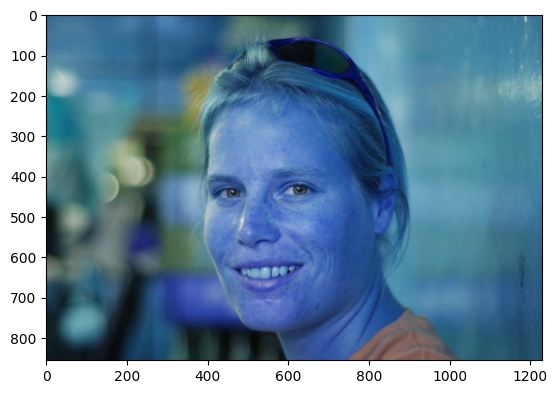

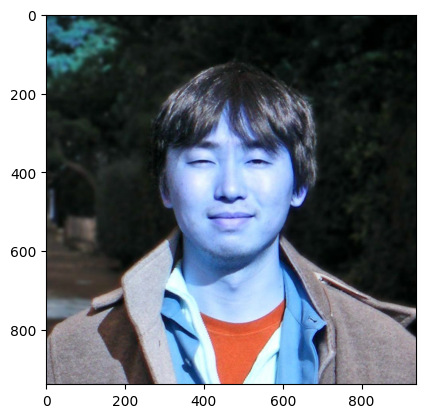

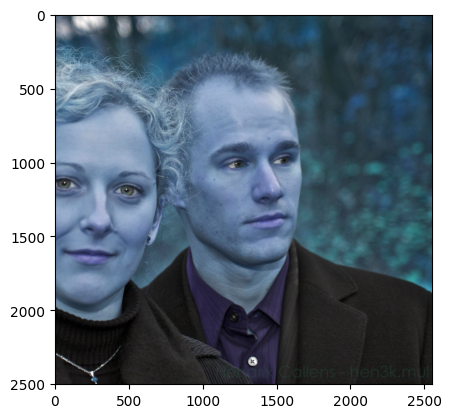

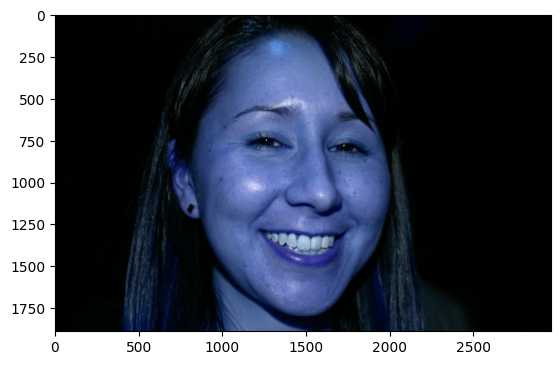

In [17]:
#visualize first four sample images from train data
for idx, image in enumerate(os.listdir(os.path.join(image_dir, "train"))):
    img = cv2.imread(os.path.join(image_dir,"train", image), 1)
    plt.imshow(img)
    plt.show()

    if idx == 3:
        break

In [15]:
for split in ["train", "val"]:

    img_folder = os.path.join(image_dir, split)
    lbl_folder = os.path.join(label_dir, split)

    images = [
        os.path.splitext(f)[0]
        for f in os.listdir(img_folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    labels = [
        os.path.splitext(f)[0]
        for f in os.listdir(lbl_folder)
        if f.endswith(".txt")
    ]

    missing_labels = set(images) - set(labels)
    missing_images = set(labels) - set(images)

    print(f"\n{split.upper()} DATASET")
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Missing labels:", len(missing_labels))
    print("Missing images:", len(missing_images))

    if missing_labels:
        print("Images without labels:", missing_labels)

    if missing_images:
        print("Labels without images:", missing_images)


TRAIN DATASET
Images: 77
Labels: 77
Missing labels: 0
Missing images: 0

VAL DATASET
Images: 0
Labels: 0
Missing labels: 0
Missing images: 0


In [16]:
train_label_dir = os.path.join(label_dir, "train")

sample_labels = sorted(os.listdir(train_label_dir))[:5]

for filename in sample_labels:

    label_path = os.path.join(train_label_dir, filename)

    print("\n", filename)

    with open(label_path, "r") as f:
        print(f.read())


 1421150832_1_jpg.rf.hKZgvVI3ezQCxdywwB3a.txt
0 0.516763 0.376436 0.344727 0.213678

 2150058510_1_jpg.rf.P5KmomERWGUMJFAD4RC2.txt
0 0.615234 0.491397 0.358073 0.068826

 2151607444_1_jpg.rf.lzGdO7qgIjm4KQBut2LH.txt
1 0.488871 0.435731 0.259599 0.093954

 2184781988_1_jpg.rf.7ux5rgYnY1VTUkFPnj2y.txt
0 0.508286 0.364303 0.229857 0.095385

 2196749951_1_jpg.rf.cgzPeOONEzdRsrtgWlr5.txt
0 0.528600 0.378472 0.203034 0.055556


### Testing

In [ ]:
!yolo predict model=yolov8n.pt source='https://ultralytics.com/images/zidane.jpg' save=True

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs

Found https://ultralytics.com/images/zidane.jpg locally at zidane.jpg
image 1/1 /content/drive/MyDrive/Colab Notebooks/zidane.jpg: 384x640 2 persons, 1 tie, 9.0ms
Speed: 89.7ms preprocess, 9.0ms inference, 36.5ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /content/drive/MyDrive/Colab Notebooks/runs/detect/predict-2
💡 Learn more at https://docs.ultralytics.com/modes/predict


## Prepared Training

In [ ]:
model = YOLO('yolov8s.pt')

# replace with actual location of data.yaml file
# adjust hyperparameters after the baseline run
results = model.train(
    data='/content/drive/MyDrive/blink-detector/dataset/data.yaml',
    epochs=50,
    imgsz=640,
    batch=8,
    patience=10,
    project='/content/drive/MyDrive/blink-detector/runs',
    name='blink_detection'
)

## Validate model accuracy

In [ ]:
metrics = model.val()

### Test on images



In [ ]:
model = YOLO("/content/runs/detect/blink_detection/weights/best.pt")

results = model.predict(
    source="/content/drive/MyDrive/blink-detector/test_image.jpg",
    conf=0.25,
    save=True,
    show_labels=True
)